In [1]:
import numpy as np 
import pandas as pd 

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

In [2]:
import pandas as pd
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
df = pd.read_csv("diabetes.csv")

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Pregnancies    768 non-null    int64  
 1   Glucose        768 non-null    int64  
 2   BloodPressure  768 non-null    int64  
 3   SkinThickness  768 non-null    int64  
 4   Insulin        768 non-null    int64  
 5   BMI            768 non-null    float64
 6   Pedigree       768 non-null    float64
 7   Age            768 non-null    int64  
 8   Outcome        768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

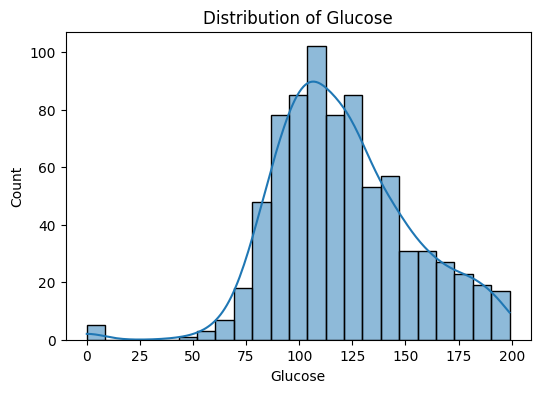

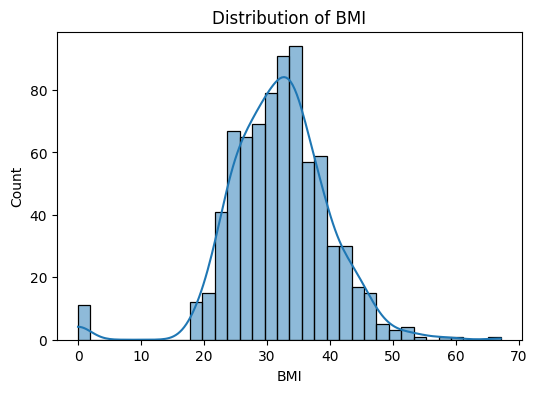

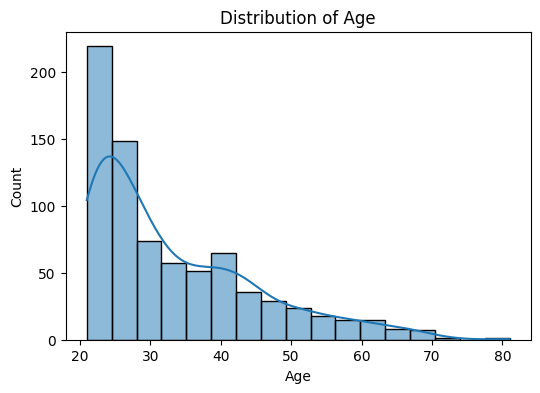

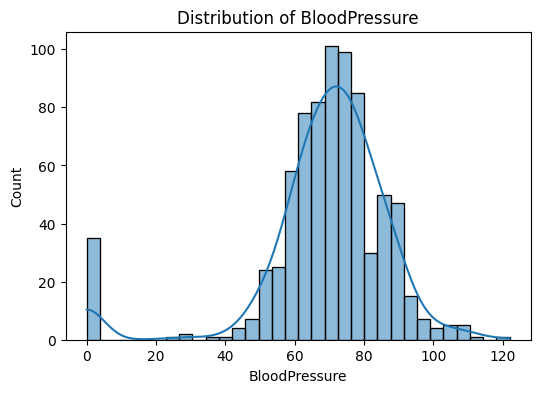

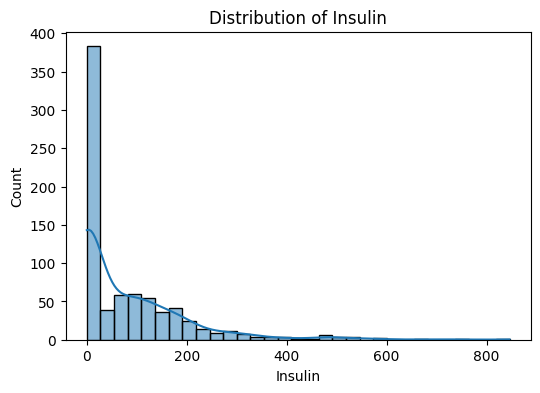

In [5]:
# Features to visualize
features = ['Glucose', 'BMI', 'Age', 'BloodPressure', 'Insulin']

# Plotting distributions
for feature in features:
    plt.figure(figsize=(6,4))
    sns.histplot(df[feature], kde=True)
    plt.title(f'Distribution of {feature}')
    plt.show()

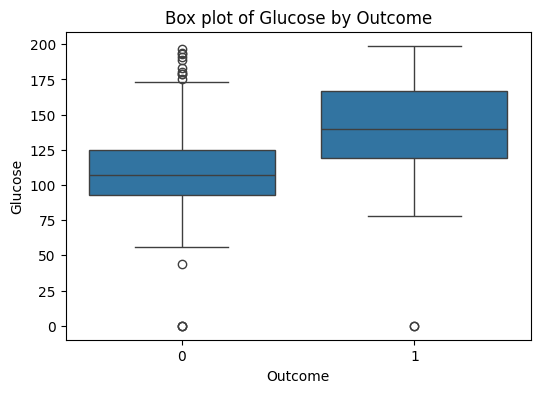

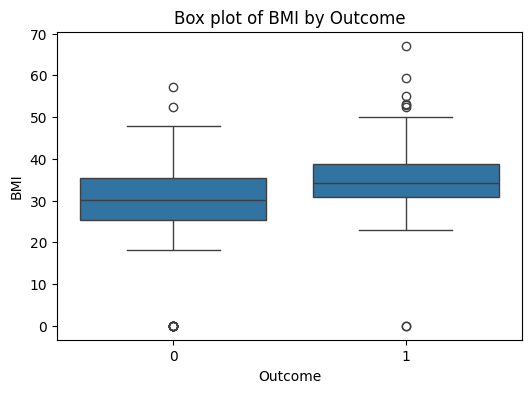

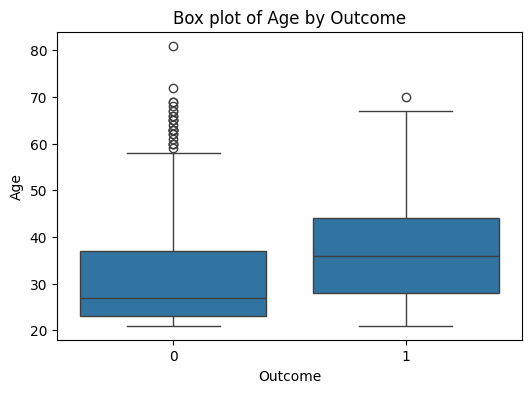

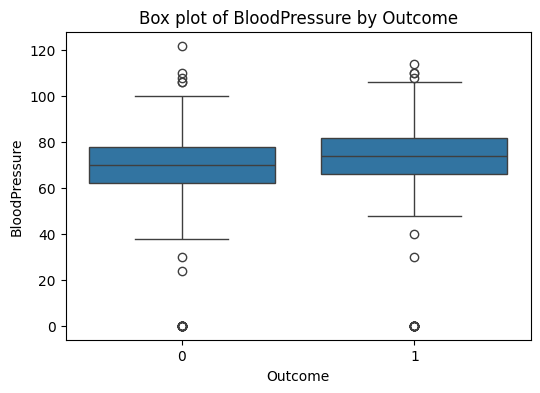

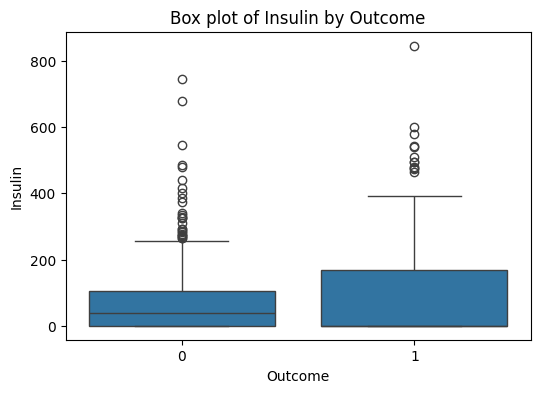

In [6]:
for feature in features:
    plt.figure(figsize=(6,4))
    sns.boxplot(data=df, x='Outcome', y=feature)
    plt.title(f'Box plot of {feature} by Outcome')
    plt.show()

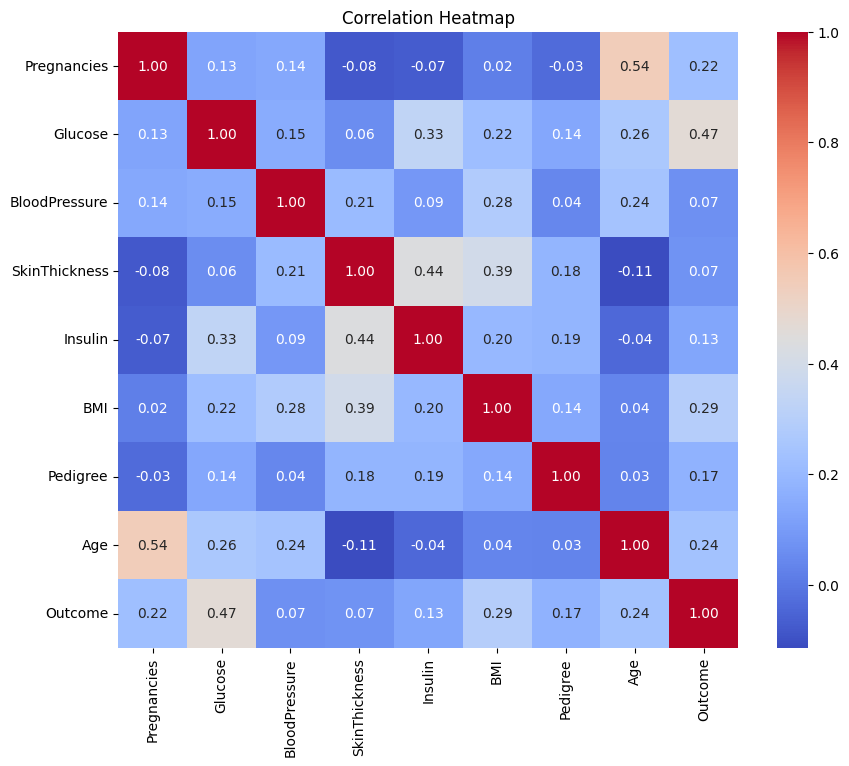

In [7]:
corr_matrix = df.corr()

# Plot the heatmap
plt.figure(figsize=(10,8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

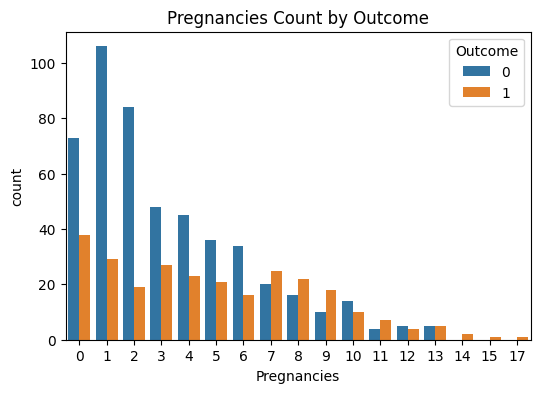

In [8]:
plt.figure(figsize=(6,4))
sns.countplot(data=df, x='Pregnancies', hue='Outcome')
plt.title('Pregnancies Count by Outcome')
plt.show()

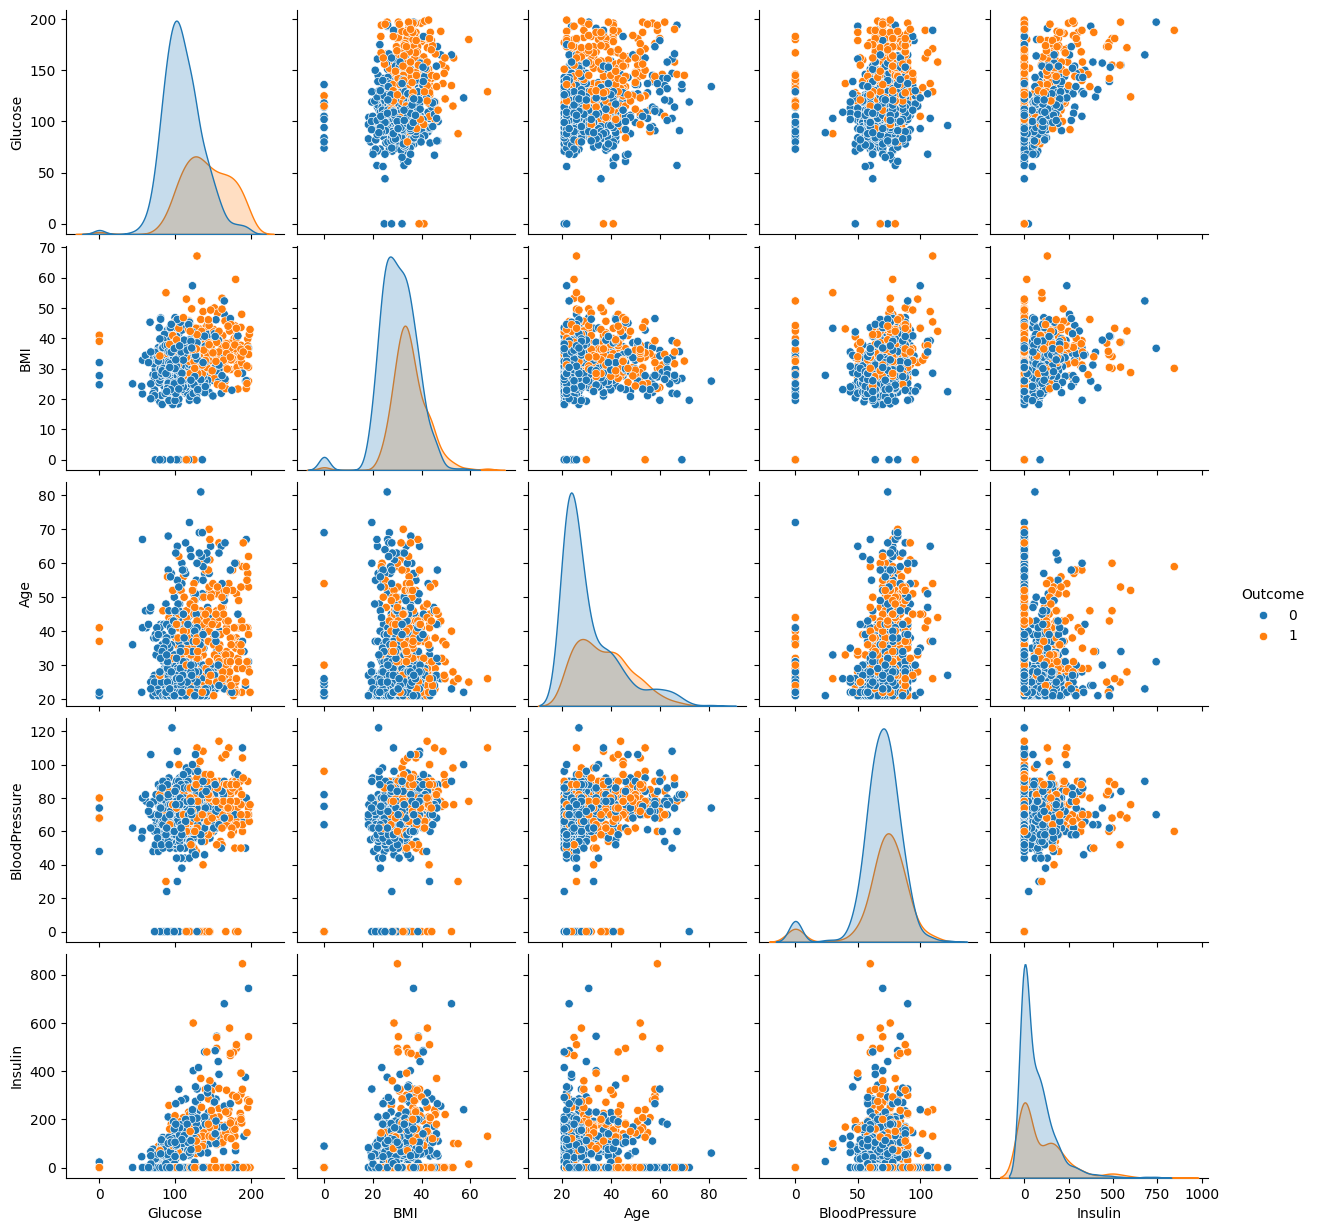

In [9]:
sns.pairplot(df, hue='Outcome', vars=['Glucose', 'BMI', 'Age', 'BloodPressure', 'Insulin'])
plt.show()

In [10]:
X = df.drop('Outcome', axis=1)
y = df['Outcome']

In [11]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [12]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [13]:
knn = KNeighborsClassifier(n_neighbors=18)
knn.fit(X_train, y_train)

KNeighborsClassifier(n_neighbors=18)

In [14]:
y_pred = knn.predict(X_test)

In [15]:
error_rates = []

for k in range(1, 21):
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train, y_train)
    y_pred_k = knn.predict(X_test)
    error_rates.append(np.mean(y_pred_k != y_test))

print('Error rates for different k:', error_rates)

Error rates for different k: [np.float64(0.37662337662337664), np.float64(0.34415584415584416), np.float64(0.2922077922077922), np.float64(0.2987012987012987), np.float64(0.3051948051948052), np.float64(0.2987012987012987), np.float64(0.3181818181818182), np.float64(0.2922077922077922), np.float64(0.3181818181818182), np.float64(0.3116883116883117), np.float64(0.2922077922077922), np.float64(0.2792207792207792), np.float64(0.2922077922077922), np.float64(0.2727272727272727), np.float64(0.2792207792207792), np.float64(0.2532467532467532), np.float64(0.24675324675324675), np.float64(0.24025974025974026), np.float64(0.24025974025974026), np.float64(0.24025974025974026)]


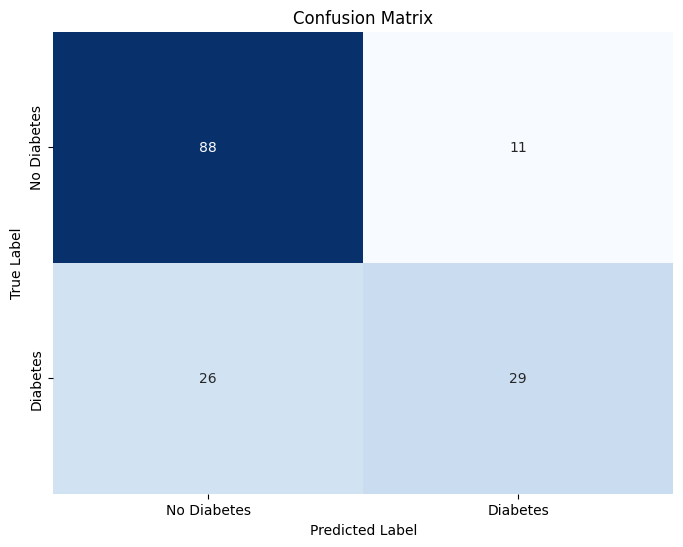

In [16]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# Compute confusion matrix
conf_matrix = confusion_matrix(y_test, y_pred)

# Plot the confusion matrix using a heatmap
plt.figure(figsize=(8,6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', cbar=False, 
            xticklabels=['No Diabetes', 'Diabetes'], 
            yticklabels=['No Diabetes', 'Diabetes'])

plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

In [17]:
accuracy = accuracy_score(y_test, y_pred)
error_rate = 1 - accuracy
print('Accuracy:', accuracy)
print('Error Rate:', error_rate)

Accuracy: 0.7597402597402597
Error Rate: 0.24025974025974028


In [18]:
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
print('Precision:', precision)
print('Recall:', recall)

Precision: 0.725
Recall: 0.5272727272727272
